# 3. Evaluación en la validación propia, experimento de inferencia y análisis de errores

Métrica: **EX ponderada** (fácil 1, media 2, difícil 3) con las reglas del enunciado: orden de filas solo si la
pregunta lo pide, números redondeados a 2 decimales, una columna adicional no penaliza (`scripts/evaluar.py`).

In [1]:
import json, os, sys
from pathlib import Path
import pandas as pd
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ); sys.path.insert(0, "scripts")
PASOS_PESADOS = False  # True para regenerar todo (requiere MySQL 8.4.10 en Docker y GPU)
pd.set_option("display.max_colwidth", 120)

In [2]:
if PASOS_PESADOS:
    !python scripts/evaluar_modelo.py --nombre baseline --sin-adapter
    !python scripts/evaluar_modelo.py --nombre lora_attn --adapter checkpoints/lora_attn/adapter
    !python scripts/evaluar_modelo.py --nombre lora_all --adapter checkpoints/lora_all/adapter
    !python scripts/evaluar_modelo.py --nombre lora_all_autocorreccion --adapter checkpoints/lora_all/adapter --autocorreccion
    !python scripts/evaluar_modelo.py --nombre baseline_autocorreccion --sin-adapter --autocorreccion
    !python scripts/evaluar_modelo.py --nombre final --adapter checkpoints/lora_final/adapter
    !python scripts/evaluar_modelo.py --nombre final_autocorreccion --adapter checkpoints/lora_final/adapter --autocorreccion
    !python scripts/evaluar_modelo.py --nombre final_fp16_autocorreccion --adapter adapter/ --autocorreccion --fp16
    !python scripts/evaluar_modelo.py --nombre baseline_fp16_autocorreccion --sin-adapter --autocorreccion --fp16
r = json.loads(Path("resultados/resumen.json").read_text(encoding="utf8"))
tabla = pd.DataFrame(r).T[["EX_ponderada", "EX_simple", "por_nivel", "ejecutan", "segundos_promedio", "segundos_max", "dtype"]]
tabla["dtype"] = tabla["dtype"].fillna("bf16")
tabla

,EX_ponderada,EX_simple,por_nivel,ejecutan,segundos_promedio,segundos_max,dtype
baseline,0.325,0.4,"{'facil': '7/12', 'media': '8/16', 'dificil': '1/12'}",22,3.05,6.79,bf16
lora_attn,0.3875,0.475,"{'facil': '10/12', 'media': '6/16', 'dificil': '3/12'}",30,1.86,3.71,bf16
lora_all,0.45,0.55,"{'facil': '10/12', 'media': '10/16', 'dificil': '2/12'}",32,1.81,3.82,bf16
lora_all_autocorreccion,0.5,0.6,"{'facil': '10/12', 'media': '12/16', 'dificil': '2/12'}",34,2.68,12.79,bf16
baseline_autocorreccion,0.375,0.475,"{'facil': '9/12', 'media': '9/16', 'dificil': '1/12'}",27,4.63,11.63,bf16
final,0.525,0.625,"{'facil': '11/12', 'media': '11/16', 'dificil': '3/12'}",32,1.89,4.62,bf16
final_autocorreccion,0.55,0.65,"{'facil': '11/12', 'media': '12/16', 'dificil': '3/12'}",35,3.11,18.07,bf16
final_fp16_autocorreccion,0.6125,0.7,"{'facil': '11/12', 'media': '13/16', 'dificil': '4/12'}",36,2.73,13.09,fp16
baseline_fp16_autocorreccion,0.3125,0.425,"{'facil': '9/12', 'media': '8/16', 'dificil': '0/12'}",27,4.72,12.97,fp16


**Experimento de inferencia (autocorrección con `ejecutar`):** si la consulta falla, se le muestra el error de MySQL al
modelo y se regenera (máx. 3 llamadas). Mejora +0.05 en baseline y en B, y +0.025 en el final. Arregla columnas
inexistentes, no errores semánticos. Mejora del adapter frente al base con autocorrección: +0.175 (bf16) / +0.30 (fp16).

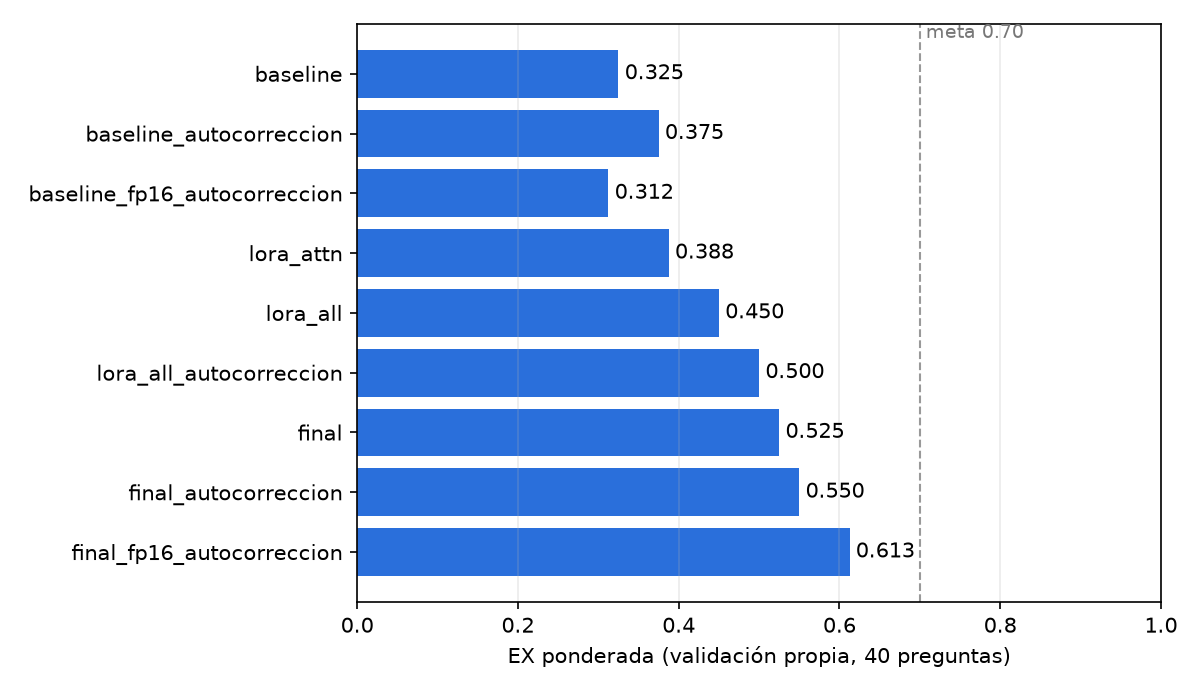

In [3]:
from IPython.display import Image
Image("resultados/ex_comparacion.png")

## Errores por categoría

In [4]:
pd.DataFrame({k: v["errores_por_categoria"] for k, v in r.items()}).fillna(0).astype(int)

,baseline,lora_attn,lora_all,lora_all_autocorreccion,baseline_autocorreccion,final,final_autocorreccion,final_fp16_autocorreccion,baseline_fp16_autocorreccion
columna o tabla inexistente,17,10,7,5,13,8,4,3,13
JOIN,5,6,6,6,6,4,5,4,8
sintaxis,1,0,1,1,0,0,1,1,0
filtro,1,2,3,3,1,2,2,2,1
resultado distinto,0,3,1,1,0,0,0,0,0
agregacion,0,0,0,0,1,1,2,2,1


In [5]:
final = pd.read_csv("resultados/validacion_propia.csv")
final[~final.correcta][["nivel", "categoria_error", "pregunta", "sql_generada", "sql_referencia", "error_mysql"]]

,nivel,categoria_error,pregunta,sql_generada,sql_referencia,error_mysql
5,facil,filtro,"Muestra, sin repetir, los códigos de descuento que se han utilizado en la compra de entradas.",SELECT DISTINCT disc_code FROM ticket,SELECT DISTINCT disc_code FROM ticket WHERE disc_code IS NOT NULL,NaN
10,media,columna o tabla inexistente,"Muestra el nombre y el apellido, sin repetir, de los asistentes que compraron alguna entrada VIP para un evento real...","SELECT DISTINCT t.att_first_name, t.att_last_name FROM ticket t JOIN attendee a ON t.att_id = a.att_id JOIN evt e ON...","SELECT DISTINCT a.first_name, a.last_name FROM attendee a JOIN ticket t ON t.att_id = a.att_id JOIN evt e ON e.evt_i...","(1054, ""Unknown column 't.att_first_name' in 'field list'"")"
16,dificil,JOIN,"Para cada evento con entradas vendidas, muestra el título del evento, el nombre y el apellido del asistente que comp...","WITH c AS (SELECT e.title, a.first_name, a.last_name, t.purchase_ts, ROW_NUMBER() OVER (PARTITION BY t.evt_id ORDER ...","WITH orden AS (SELECT t.evt_id, t.att_id, t.purchase_ts, ROW_NUMBER() OVER (PARTITION BY t.evt_id ORDER BY t.purchas...",NaN
17,dificil,filtro,"Para cada evento ya realizado (completed), ¿con cuántos días de anticipación en promedio se compraron sus entradas p...","SELECT e.title, ROUND(AVG(DATEDIFF(e.start_dt, t.purchase_ts)), 2) AS dias_promedio FROM ticket t JOIN evt e ON t.ev...","SELECT e.title, ROUND(AVG(DATEDIFF(e.start_dt, t.purchase_ts)), 2) AS dias_anticipacion FROM evt e JOIN ticket t ON ...",NaN
18,dificil,JOIN,"Para cada evento, muestra el título, la categoría, la fecha de inicio, el precio base y la diferencia entre su preci...","WITH r AS (SELECT e.*, LAG(e.base_price) OVER (PARTITION BY e.cat ORDER BY e.start_dt) AS dif FROM evt e) SELECT tit...","SELECT title, cat, start_dt, base_price, base_price - LAG(base_price) OVER (PARTITION BY cat ORDER BY start_dt) AS d...",NaN
19,dificil,JOIN,"Lista el título de la sesión, el nombre completo del ponente y la duración de las sesiones que duran más que el prom...","WITH x AS (SELECT s.session_id, s.title, sp.full_name, s.dur_min, s.evt_id, ROW_NUMBER() OVER (PARTITION BY s.evt_id...","SELECT se.title, sp.full_name, se.dur_min FROM session se LEFT JOIN speaker sp ON sp.spk_id = se.spk_id WHERE se.dur...",NaN
31,media,columna o tabla inexistente,¿Cuál es el kilometraje promedio con el que ingresan los vehículos al taller según su tipo de combustible? Devuelve ...,"SELECT comb, ROUND(AVG(km), 2) AS km_promedio FROM veh GROUP BY comb","SELECT v.comb, ROUND(AVG(o.km), 2) AS km_promedio FROM veh v JOIN ord_srv o ON o.id_veh = v.id_veh GROUP BY v.comb","(1054, ""Unknown column 'km' in 'field list'"")"
32,media,JOIN,"Por cada ciudad, muestra la ciudad y el número de clientes distintos que llevaron al menos un vehículo al taller dur...","SELECT ciu, COUNT(DISTINCT id_cli) AS num_clientes FROM cli WHERE YEAR(f_reg) = 2024 GROUP BY ciu","SELECT c.ciu, COUNT(DISTINCT c.id_cli) AS num_clientes FROM cli c JOIN veh v ON v.id_cli = c.id_cli JOIN ord_srv o O...",NaN
34,dificil,sintaxis,"Calcula el gasto total de cada cliente en órdenes entregadas, sumando la mano de obra y los repuestos (cantidad por ...","SELECT c.nom, c.ape, SUM(o.costo_mo + SUM(d.cant * d.p_unit)) AS gasto FROM ord_srv o JOIN veh v ON o.id_veh = v.id_...","WITH rep_ord AS (SELECT id_ord, SUM(cant * p_unit) AS total_rep FROM det_ord GROUP BY id_ord), gasto AS (SELECT v.id...","(1111, 'Invalid use of group function')"
35,dificil,agregacion,"Lista el número de orden, la placa del vehículo y el costo de mano de obra de las órdenes entregadas cuyo costo de m...","SELECT id_ord, v.placa, o.costo_mo FROM ord_srv o JOIN veh v ON v.id_veh = o.id_veh WHERE o.est = 'Entregada'","SELECT o.id_ord, v.placa, o.costo_mo FROM ord_srv o JOIN veh v ON v.id_veh = o.id_veh WHERE o.est = 'Entregada' AND ...",NaN


## Comparación por pregunta: baseline vs. modelo final

In [6]:
base = pd.read_csv("resultados/baseline.csv")
comp = pd.DataFrame({"nivel": base.nivel, "pregunta": base.pregunta, "baseline": base.correcta, "final": final.correcta})
print("arregladas:", int((~comp.baseline & comp.final).sum()), "| empeoradas:", int((comp.baseline & ~comp.final).sum()))
comp[comp.baseline != comp.final]

arregladas: 12 | empeoradas: 0


,nivel,pregunta,baseline,final
0,facil,"Lista el nombre, la ciudad y el aforo de los recintos con capacidad para más de 5000 personas.",False,True
1,facil,¿Cuántas entradas han sido reembolsadas? Devuelve solo el número.,False,True
4,facil,¿Cuál es la duración promedio en minutos de las sesiones de tipo taller (workshop)? Devuelve el valor redondeado a 2...,False,True
9,media,"Para los eventos ya realizados (completed), muestra por cada país del recinto el país, el número de eventos y el pre...",False,True
11,media,"Para cada evento patrocinado, muestra el título del evento, el número de patrocinadores y el monto total aportado po...",False,True
12,media,¿Desde qué países de residencia de los asistentes se han pagado más de 1500 dólares en entradas? Devuelve el país y ...,False,True
13,media,"Muestra el nombre de cada patrocinador y en cuántos eventos ha participado como patrocinador, incluyendo a los que t...",False,True
15,dificil,El ingreso total de un evento es la suma de sus entradas pagadas más los aportes de sus patrocinadores. Muestra el t...,False,True
20,facil,"Lista la placa, la marca y el modelo de los vehículos fabricados antes del año 2012.",False,True
30,media,"Para cada marca de vehículo, muestra la marca y el monto total cobrado en repuestos (cantidad por precio unitario co...",False,True


## Predicción para la evaluación oculta

EX ≈ 0.55 con adapter (intervalo 0.42–0.68) y ≈ 0.33 sin adapter. La justificación completa está en el README §8: por
nivel, fácil ≈ 92 %, media ≈ 75–80 %, difícil ≈ 25–33 %. El error estándar es ≈ 0.08 con 30–40 preguntas (la sola
diferencia bf16/fp16 mueve 6 puntos). Nuestras trampas pueden ser más duras que las del docente, pero el estilo de la
validación se parece al del entrenamiento.